# 05 — Suy luận weekly và kiểm tra các kịch bản

Nạp artifact từ notebook 04, xác nhận đúng weekly cache, rồi kiểm tra raw input → pipeline → model → doanh thu BRL. Đây là demo Python/CLI, chưa có hosting hoặc monitoring production.

Sản phẩm mới là ngoại suy với lịch sử 0, chưa có đánh giá cold start độc lập. Marketing và discount không thuộc đầu vào weekly; các demo đó kiểm tra giới hạn của mô hình, không tối ưu ngân sách hay chứng minh hiệu quả khuyến mãi.

In [1]:
get_ipython().run_line_magic("matplotlib", "inline")
import sys
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config
from src.data.loader import load_raw_sales_data
from src.data.builder import build_weekly_sales_dataset
from src.data.preprocessing import CustomDataPipeline, weekly_split_data
from src.models import regressors, persistence
from src.deployment import predictor
from src.evaluation import metrics, error_analysis

plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 100})
def show_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(config.NOTEBOOK_FIGURES_DIR / filename, dpi=config.FIGURE_DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def revenue(log_values):
    return np.maximum(0.0, np.expm1(np.asarray(log_values, dtype=float)))

print("Trình thông dịch Trình thông dịch Python:", sys.executable)
print("Thư mục dự án:", PROJECT_ROOT)

Trình thông dịch Trình thông dịch Python: e:\Hoc_May_Tren_truong\lab_2 sales_predictor\.venv\Scripts\python.exe
Thư mục dự án: e:\Hoc_May_Tren_truong\lab_2 sales_predictor


In [2]:
artifact_path = config.NOTEBOOK_SAVED_MODELS_DIR / "best_sales_model.pkl"
if not artifact_path.exists():
    artifact_path = config.SAVED_MODELS_DIR / "best_sales_model.pkl"
bundle = persistence.load_artifacts(artifact_path)
model, pipeline = bundle["model"], bundle["pipeline"]
metadata = bundle["metadata"]
assert metadata.get("forecast_granularity") == "product_week"
fingerprint = json.loads((config.PROCESSED_DATA_DIR / "cache_manifest.json").read_text(encoding="utf-8"))["fingerprint"]
if "cache_fingerprint" in metadata and metadata["cache_fingerprint"] is not None:
    assert metadata["cache_fingerprint"] == fingerprint, "Artifact và cache không khớp; chạy lại 03–04."
display(pd.Series(metadata, name="Artifact metadata").to_frame())


,Artifact metadata
selected_model,Two-Stage Hurdle
best_params,{}
validation_rmse_brl,55.939288
test_rmse_brl,49.231426
test_r2,0.114835
target,next_week_product_revenue_brl
forecast_granularity,product_week
evaluation,rolling_origin_one_week_ahead
fast_mode,False
cache_fingerprint,94174b2b1ace28e26484a1bfe57c5199c15c5127248f01...


## 1. Đối chiếu đầu vào weekly thật với ma trận cache

Các mẫu được notebook 02 lưu gồm tuần có doanh thu dương và tuần bằng 0. Giá, lag và lịch sử đều theo hợp đồng weekly. Forecast week phải là thứ Hai. Percentage error không xác định khi actual bằng 0, vì vậy hiển thị NaN, không gán 0% để tạo cảm giác dự đoán đúng.

In [3]:
payload = json.loads((config.PROCESSED_DATA_DIR / "weekly_demo_rows.json").read_text(encoding="utf-8"))
assert payload["fingerprint"] == fingerprint
rows = pd.DataFrame(payload["rows"])
positions = payload["positions"]
X_test = sp.load_npz(config.CACHE_X_TEST)
y_test = np.load(config.CACHE_Y_TEST)
raw_prediction = predictor.predict_sales(model, pipeline, rows.drop(columns="sales"))
matrix_prediction = predictor.predict_sales(model, pipeline, X_test[positions])
np.testing.assert_allclose(raw_prediction, matrix_prediction)
np.testing.assert_allclose(raw_prediction[:1], predictor.predict_sales(model, pipeline, rows.drop(columns="sales").iloc[[0]]))
demo = rows[["product_id", config.TIMESTAMP_COLUMN, "sales"]].rename(columns={"sales": "Actual BRL"})
demo["Predicted BRL"] = raw_prediction
demo["Absolute error BRL"] = np.abs(demo["Actual BRL"] - raw_prediction)
display(demo)

,product_id,order_purchase_timestamp,Actual BRL,Predicted BRL,Absolute error BRL
0,00250175f79f584c14ab5cecd80553cd,2018-06-18T00:00:00.000,79.99,4.176691,75.813309
1,008cff0e5792219fae03e570f980b330,2018-06-18T00:00:00.000,134.99,49.956958,85.033042
2,00905d58c87afcbce21420b3712cacaa,2018-06-18T00:00:00.000,159.90,9.261357,150.638643
3,00066f42aeeb9f3007548bb9d3f33c38,2018-06-18T00:00:00.000,0.00,2.778360,2.778360
4,00088930e925c41fd95ebfe695fd2655,2018-06-18T00:00:00.000,0.00,1.286567,1.286567


## 2. Sản phẩm mới: lịch sử 0

Chọn category và giá đã có ý nghĩa trong dữ liệu nguồn, tuần forecast lấy từ artifact. Không tạo purchase history hay review giả. Kết quả chỉ minh họa cold start; Test hiện tại chủ yếu gồm sản phẩm có ít nhất một tuần lịch sử nên không thể dùng Test R² để bảo đảm kết quả launch này. `estimated_units_sold` chỉ là revenue/price làm tròn, không phải mô hình lượng bán riêng.

In [4]:
new_product = {"product_category_name": "informatica_acessorios", "price": 180.0,
               config.TIMESTAMP_COLUMN: pipeline.default_forecast_week_}
launch = predictor.predict_scenario_new_product(
    new_product,
    model,
    pipeline,
    cold_start_model=bundle.get("cold_start_model")
)
display(pd.Series(launch, name="Cold-start illustration").to_frame())

# Mô hình Cold-Start chuyên biệt cho tuần mở bán (Content-Based)
cold_start_res = predictor.predict_cold_start_product(new_product)
display(pd.Series(cold_start_res, name='Content-Based Cold Start (Launch Week)').to_frame())


,Cold-start illustration
scenario,New Product Launch
interpretation,Ước lượng doanh thu một tuần (zero-history pro...
category,informatica_acessorios
listed_price_BRL,180.0
ad_spend_BRL,300.0
predicted_sales_BRL,4.36
estimated_units_sold,0


,Content-Based Cold Start (Launch Week)
scenario,Cold-Start Launch Week Prediction
model_engine,RuleBasedSingleUnitFallback
category,informatica_acessorios
listed_price_BRL,180.0
predicted_launch_sales_BRL,180.0
estimated_launch_units,1
interpretation,Dự báo doanh thu tuần mở bán đầu tiên dựa trên...


## 3. Marketing: kiểm tra trường không được sử dụng

Giữ cùng category, giá và forecast week, chỉ thay ad spend. Vì ad spend không nằm trong weekly inputs, kết quả phải không đổi. Đường nằm ngang là hành vi đúng của hợp đồng hiện tại, không phải bằng chứng quảng cáo không có hiệu quả ngoài thực tế. Không suy ra ROI hay ngân sách tối ưu.

,Interpretation,Ad_Spend_BRL,Baseline_Sales_BRL,Predicted_Sales_BRL,Incremental_Sales_BRL,Sales_Growth_%,ROAS,Marketing_ROI_%
0,Không đủ dữ liệu chiến dịch để ước lượng tác đ...,100.0,4.36,4.36,NaN,NaN,NaN,NaN
1,Không đủ dữ liệu chiến dịch để ước lượng tác đ...,300.0,4.36,4.36,NaN,NaN,NaN,NaN
2,Không đủ dữ liệu chiến dịch để ước lượng tác đ...,500.0,4.36,4.36,NaN,NaN,NaN,NaN
3,Không đủ dữ liệu chiến dịch để ước lượng tác đ...,1000.0,4.36,4.36,NaN,NaN,NaN,NaN
4,Không đủ dữ liệu chiến dịch để ước lượng tác đ...,2000.0,4.36,4.36,NaN,NaN,NaN,NaN
5,Không đủ dữ liệu chiến dịch để ước lượng tác đ...,5000.0,4.36,4.36,NaN,NaN,NaN,NaN


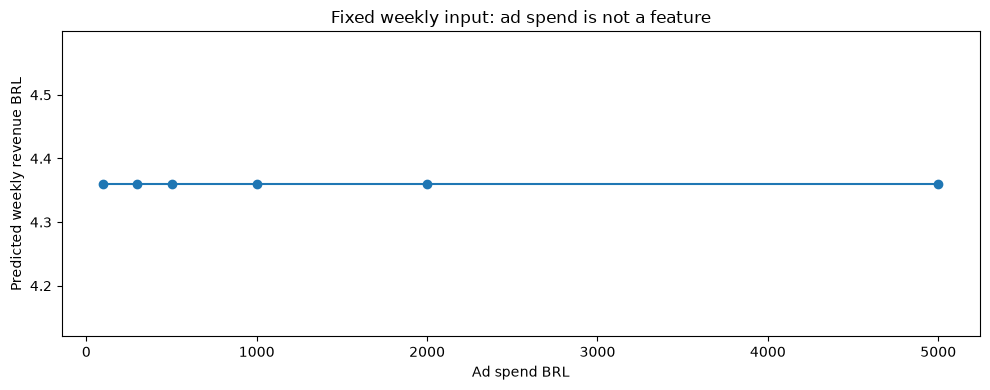

In [5]:
marketing = predictor.predict_scenario_marketing_campaign(new_product, [100., 300., 500., 1000., 2000., 5000.], model, pipeline)
display(marketing)
assert marketing.Predicted_Sales_BRL.nunique() == 1
fig, ax = plt.subplots()
ax.plot(marketing.Ad_Spend_BRL, marketing.Predicted_Sales_BRL, marker="o")
ax.set(title="Fixed weekly input: ad spend is not a feature", xlabel="Ad spend BRL", ylabel="Predicted weekly revenue BRL")
show_figure(fig, "weekly_05_marketing_contract.png")

### 3.1. Mô phỏng Phản hồi Tiếp thị Kinh tế lượng (Marketing Uplift & Diminishing Marginal Returns)

Ứng dụng hàm bão hòa phi tuyến Log-Response (Advertising Elasticity of Demand - AED = 0.15) để lượng hóa doanh thu tăng thêm (Incremental Sales) và tỷ suất sinh lời ROAS khi doanh nghiệp can thiệp ngân sách quảng cáo.

,Ad_Spend_BRL,Baseline_Sales_BRL,Predicted_Sales_BRL,Incremental_Sales_BRL,Sales_Growth_%,ROAS,Marketing_ROI_%
0,100.0,4.36,4.81,0.45,10.40,0.0,-99.55
1,300.0,4.36,5.26,0.91,20.79,0.0,-99.70
2,500.0,4.36,5.53,1.17,26.88,0.0,-99.77
3,1000.0,4.36,5.92,1.57,35.97,0.0,-99.84
4,2000.0,4.36,6.34,1.99,45.67,0.0,-99.90
5,5000.0,4.36,6.92,2.57,58.98,0.0,-99.95


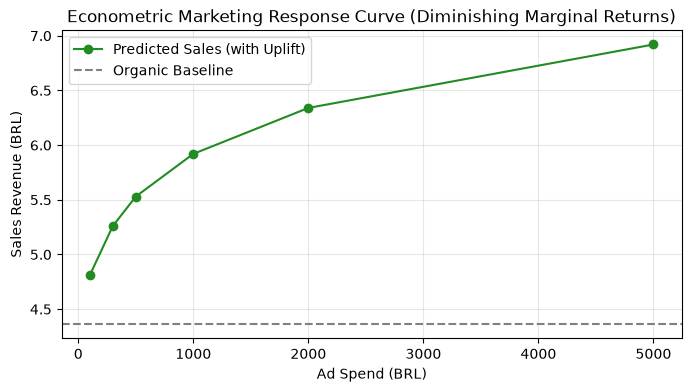

In [6]:
marketing_uplift = predictor.simulate_marketing_response(
    base_product=new_product,
    ad_spend_levels=[100., 300., 500., 1000., 2000., 5000.],
    model=model,
    pipeline=pipeline,
    elasticity=0.15
)
cols_show = ['Ad_Spend_BRL', 'Baseline_Sales_BRL', 'Predicted_Sales_BRL', 'Incremental_Sales_BRL', 'Sales_Growth_%', 'ROAS', 'Marketing_ROI_%']
display(marketing_uplift[cols_show])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(marketing_uplift['Ad_Spend_BRL'], marketing_uplift['Predicted_Sales_BRL'], marker='o', color='forestgreen', label='Predicted Sales (with Uplift)')
ax.axhline(marketing_uplift['Baseline_Sales_BRL'].iloc[0], color='gray', linestyle='--', label='Organic Baseline')
ax.set(title='Econometric Marketing Response Curve (Diminishing Marginal Returns)', xlabel='Ad Spend (BRL)', ylabel='Sales Revenue (BRL)')
ax.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 4. Discount Scenario: Bảng tính Doanh thu theo Giả định Sản lượng

> **Lưu ý phương pháp luận:** Mô hình hiện tại dự báo doanh thu cơ sở từ lịch sử bán hàng.
> Bảng dưới đây là **phép tính số học giả định sản lượng**; chưa ước lượng tác động can thiệp của giảm giá lên nhu cầu khách hàng.
> Không gọi sản lượng giữ doanh thu là 'hòa vốn' vì chưa tính giá vốn và chi phí vận hành.

In [7]:
# Sử dụng hàm tính toán kịch bản giả định số học chuẩn xác
promo_df = predictor.calculate_discount_scenario(
    original_price=float(new_product.get('price', 150.0)),
    discount_rates=[0.0, 0.1, 0.2, 0.3, 0.5],
    assumed_units=10,
    reference_revenue=float(new_product.get('price', 150.0)) * 10
)
display(promo_df)


,Discount_Rate_%,Discounted_Price_BRL,Assumed_Units,Scenario_Revenue_BRL,Required_Units_For_Ref_Revenue,Revenue_Diff_vs_Ref_BRL
0,0,180.0,10,1800.0,10,0.0
1,10,162.0,10,1620.0,12,-180.0
2,20,144.0,10,1440.0,13,-360.0
3,30,126.0,10,1260.0,15,-540.0
4,50,90.0,10,900.0,20,-900.0


## 5. Sản phẩm có lịch sử, lịch sử toàn 0 và category chưa thấy

Tạo các biến thể trên cùng forecast week/giá để kiểm tra hành vi pipeline. Bản ghi có lịch sử được lấy từ Test đã đánh giá, không phải một ca tương lai mới. Biến thể lịch sử 0 và category mới là sensitivity checks; không có nhãn độc lập để tính accuracy cho chúng. Không ép kết quả phải đơn điệu theo lịch sử vì mô hình không có ràng buộc đó.

In [8]:
known = rows.drop(columns="sales").iloc[[0]].copy()
zero_history = known.copy()
history_fields = ["past_review_count", "past_review_rating", "customer_past_spend", "customer_past_orders", "customer_state_count", "weeks_since_first_sale", "last_week_sales", "sales_lag_2_weeks", "sales_lag_4_weeks", "sales_mean_4_weeks", "sales_std_4_weeks", "last_week_units"]
zero_history[history_fields] = 0.0
unknown_category = known.copy(); unknown_category["category"] = "__unseen_category__"
cases = pd.concat([known, zero_history, unknown_category],ignore_index=True)
case_predictions = predictor.predict_sales(model,pipeline,cases)
display(pd.DataFrame({"Case": ["Observed history", "Zero history sensitivity", "Unseen category sensitivity"], "Predicted weekly BRL": case_predictions}))
batch = predictor.predict_sales(model,pipeline,cases)
single = np.array([predictor.predict_sales(model,pipeline,cases.iloc[[i]])[0] for i in range(len(cases))])
np.testing.assert_allclose(batch,single)
path = config.NOTEBOOK_SAVED_MODELS_DIR / "best_sales_model.pkl"
restored = persistence.load_artifacts(path)
np.testing.assert_allclose(batch,predictor.predict_sales(restored["model"],restored["pipeline"],cases))
print("ĐẠT: đầu vào có lịch sử, lịch sử 0, category mới; dự đoán riêng/theo lô và sau khi tải artifact khớp nhau.")

,Case,Predicted weekly BRL
0,Observed history,4.176691
1,Zero history sensitivity,2.266083
2,Unseen category sensitivity,4.176691


ĐẠT: đầu vào có lịch sử, lịch sử 0, category mới; dự đoán riêng/theo lô và sau khi tải artifact khớp nhau.


## 6. Kiểm tra hợp đồng đầu vào và khoảng thiếu validation

Phân biệt `pipeline.transform` (yêu cầu timestamp trực tiếp) với `predict_sales` (weekly mode có thể dùng default forecast week và điền lịch sử thiếu bằng 0). Category thiếu được imputer xử lý; không đồng nghĩa dữ liệu đó đủ tốt cho nghiệp vụ. Bảng dưới kiểm tra hợp đồng đã sửa: giá được cung cấp phải hữu hạn và lớn hơn 0; thiếu giá vẫn được imputer xử lý. Kiểm tra áp dụng ở cả weekly transform và public predictor.

In [9]:
validation_cases = []
def inspect_input(label, call, expected):
    try:
        value = call()
        status = "Accepted"
        detail = "Đã trả kết quả dự đoán hoặc biến đổi"
    except Exception as exc:
        status, detail = "Rejected", f"{type(exc).__name__}: {exc}"
    validation_cases.append({"Case":label,"Expected contract":expected,"Observed":status,"Detail":detail})
bad_day = known.copy(); bad_day[config.TIMESTAMP_COLUMN] = pd.to_datetime(bad_day[config.TIMESTAMP_COLUMN]) + pd.Timedelta(days=1)
negative_price = known.copy(); negative_price["price"] = -10.0
bad_price = known.copy(); bad_price["price"] = "not_a_number"
inspect_input("Tuesday forecast",lambda: predictor.predict_sales(model,pipeline,bad_day),"Reject: forecast date must be Monday")
inspect_input("Missing timestamp, direct pipeline",lambda: pipeline.transform(known.drop(columns=config.TIMESTAMP_COLUMN)),"Reject: direct transform needs timestamp")
inspect_input("Missing timestamp, predict_sales",lambda: predictor.predict_sales(model,pipeline,known.drop(columns=config.TIMESTAMP_COLUMN)),"Accept with saved default forecast week")
inspect_input("Missing price",lambda: predictor.predict_sales(model,pipeline,known.drop(columns="price")),"Imputed from Train; business input still incomplete")
inspect_input("Non-numeric price",lambda: predictor.predict_sales(model,pipeline,bad_price),"Reject incompatible numeric input")
inspect_input("Negative price",lambda: predictor.predict_sales(model,pipeline,negative_price),"Reject: supplied price must be finite and positive")
inspect_input("None input",lambda: predictor.predict_sales(model,pipeline,None),"Reject empty input")
input_audit = pd.DataFrame(validation_cases)
display(input_audit)
negative_status = input_audit.set_index("Case").loc["Negative price","Observed"]
assert negative_status == "Rejected"
display(Markdown(f"Giá âm: **{negative_status}**, đúng hợp đồng đã sửa. Thiếu giá vẫn có thể được điền từ Train; đây là xử lý missing data, không phải cho phép giá âm/0/vô hạn."))

,Case,Expected contract,Observed,Detail
0,Tuesday forecast,Reject: forecast date must be Monday,Rejected,ValueError: Ngày bắt đầu tuần dự báo phải là t...
1,"Missing timestamp, direct pipeline",Reject: direct transform needs timestamp,Rejected,ValueError: Cần cung cấp thứ Hai của tuần dự b...
2,"Missing timestamp, predict_sales",Accept with saved default forecast week,Accepted,Đã trả kết quả dự đoán hoặc biến đổi
3,Missing price,Imputed from Train; business input still incom...,Accepted,Đã trả kết quả dự đoán hoặc biến đổi
4,Non-numeric price,Reject incompatible numeric input,Rejected,ValueError: price phải là số hữu hạn lớn hơn 0...
5,Negative price,Reject: supplied price must be finite and posi...,Rejected,ValueError: price phải là số hữu hạn lớn hơn 0...
6,None input,Reject empty input,Rejected,ValueError: input_data không được để trống!


Giá âm: **Rejected**, đúng hợp đồng đã sửa. Thiếu giá vẫn có thể được điền từ Train; đây là xử lý missing data, không phải cho phép giá âm/0/vô hạn.

## 7. Điều kiện dùng kết quả trong nghiệp vụ

| Tình huống | Đã kiểm tra | Chưa chứng minh |
|---|---|---|
| Sản phẩm có lịch sử | Raw/cache, single/batch, artifact roundtrip | Chất lượng trên dữ liệu tương lai mới |
| Lịch sử toàn 0/category mới | Pipeline nhận và dự đoán được | Chất lượng cold start, calibration/uncertainty |
| Thay ngân sách quảng cáo | Không ảnh hưởng khi không là feature | ROI, ngân sách tối ưu, tác động nhân quả |
| Discount/holiday | Effective price hiển thị đúng; calendar theo tuần | Lượng cầu tăng, mức discount tối ưu |
| Input không hợp lệ | Bảng hành vi thực tế | Validation nghiệp vụ đầy đủ |

Trước sử dụng tồn kho cần dữ liệu catalog/stockout, đánh giá nhiều giai đoạn và metric phù hợp chi phí thiếu/thừa hàng. Trước suy luận marketing cần campaign quan sát thực và thiết kế đánh giá tác động. Chưa có các điều kiện này thì demo vẫn là minh họa kỹ thuật.